<a href="https://colab.research.google.com/github/rodrigoesborges/conju-python/blob/main/Grupo_1_IBC_BR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install python-bcb

In [ ]:
from bcb import sgs


In [ ]:
sgs.get(24364)

,24364
Date,
2003-01-01,70.24531
2003-02-01,71.46538
2003-03-01,71.07428
2003-04-01,70.59064
2003-05-01,69.89636
...,...
2026-04-01,111.04254
2026-05-01,111.25061
2026-06-01,110.37352


In [ ]:
import pandas as pd
from bcb import sgs

# Buscar dados da série 24364
df = sgs.get(24364)
df.index = pd.to_datetime(df.index)
col_nome = df.columns[0]

# Filtrar dados para os anos de 2025 e 2026
df_2025 = df[df.index.year == 2025].copy()
df_2026 = df[df.index.year == 2026].copy()

# Adicionar coluna de mês para fazer o alinhamento (join/merge)
df_2025['Mes'] = df_2025.index.month
df_2026['Mes'] = df_2026.index.month

# Mesclar os dados de 2025 e 2026 com base no mês
comparativo = pd.merge(df_2025, df_2026, on='Mes', suffixes=('_2025', '_2026'))

# Calcular a variação percentual
comparativo['Variacao_Anual (%)'] = ((comparativo[f'{col_nome}_2026'] / comparativo[f'{col_nome}_2025']) - 1) * 100

# Formatar e exibir os resultados
comparativo = comparativo.rename(columns={f'{col_nome}_2025': 'Valor_2025', f'{col_nome}_2026': 'Valor_2026'})
comparativo = comparativo[['Mes', 'Valor_2025', 'Valor_2026', 'Variacao_Anual (%)']]
display(comparativo)

,Mes,Valor_2025,Valor_2026,Variacao_Anual (%)
0,1,108.05509,110.15169,1.940307
1,2,108.57481,110.82485,2.072341
2,3,110.03087,110.65755,0.569549
3,4,109.51799,111.04254,1.392054
4,5,108.88849,111.25061,2.169302
5,6,108.82565,110.37352,1.422339
6,7,108.60295,110.03188,1.315738
7,8,108.84223,110.40624,1.436951


/tmp/ipykernel_620/3669209667.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


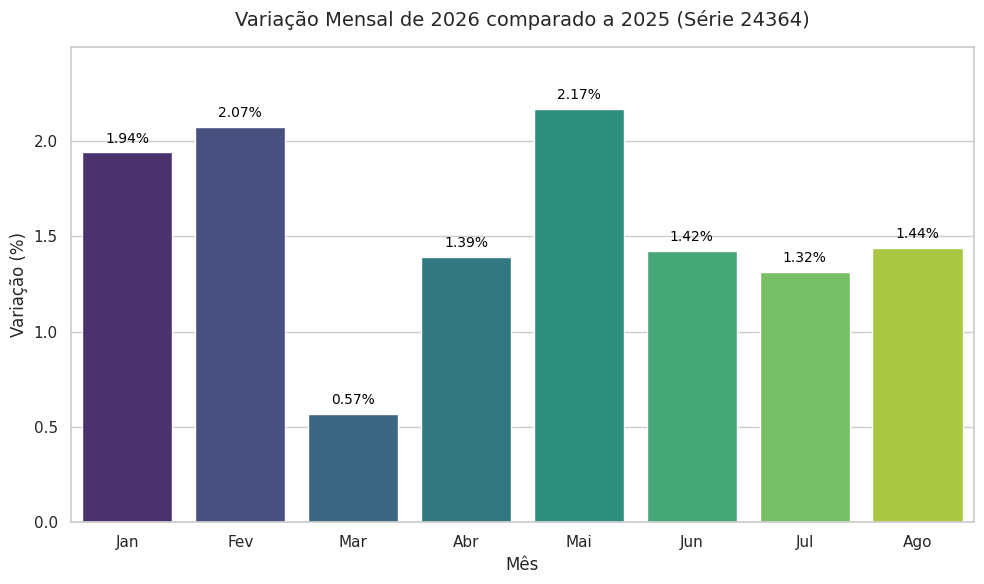

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Criar gráfico de barras
ax = sns.barplot(
    x='Mes',
    y='Variacao_Anual (%)',
    data=comparativo,
    palette='viridis'
)

# Adicionar os valores acima das barras
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 5),
                textcoords='offset points')

# Customizações estéticas
plt.title('Variação Mensal de 2026 comparado a 2025 (Série 24364)', fontsize=14, pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Variação (%)', fontsize=12)
plt.xticks(range(8), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago']) # Ajustado para os meses disponíveis
plt.ylim(0, max(comparativo['Variacao_Anual (%)']) * 1.15)

plt.tight_layout()
plt.show()